<a href="https://colab.research.google.com/github/josemartinlabarca/mineria-datos-churn-telco/blob/main/Lab_2_6_Reglas_Asociacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 Actividad 2.6 — Laboratorio: Reglas de Asociación con Apriori
**IEI097 Minería de Datos · Unidad II · Semana 08**
**Estudiante:** ✍️ *(tu nombre)*

Objetivo: extraer reglas de asociación con el algoritmo **Apriori** (librería `mlxtend`), comparar distintas configuraciones de umbrales e interpretar las reglas en lenguaje de negocio.

> ⚠️ Las credenciales de Kaggle se leen desde **Colab Secrets**; no hay ningún token escrito en este notebook.

## Fase 1 · Carga del dataset
Dataset usado: **Groceries Dataset for Market Basket Analysis** (Kaggle, autor *rashikrahmanpritom*). Son compras de un almacén: cada fila es **un producto comprado por un cliente en una fecha**.

In [ ]:
# ▶ PASO 0: ejecuta SOLO esta celda primero.
# Instala versiones compatibles con Colab y luego REINICIA la sesión automáticamente.
# Verás un aviso de "la sesión se bloqueó / se reinició": es NORMAL.
!pip install -q "numpy<2.3" "pandas==2.2.3"
!pip install -q --no-deps mlxtend
import os
os.kill(os.getpid(), 9)

> ✅ Después del reinicio automático: haz clic en la celda de abajo y usa **Entorno de ejecución → Ejecutar celda seleccionada y siguientes**. No vuelvas a ejecutar la celda de instalación.

In [1]:
import os, glob
import numpy, pandas as pd, mlxtend
import matplotlib.pyplot as plt
from google.colab import userdata
print("numpy", numpy.__version__, "| pandas", pd.__version__, "| mlxtend", mlxtend.__version__)

# Credenciales desde Colab Secrets (icono de la llave 🔑 a la izquierda)
def leer_secreto(*nombres):
    for n in nombres:
        try:
            return userdata.get(n)
        except Exception:
            pass
    return None

token   = leer_secreto("KAGGLE_API_TOKEN", "KAGGLE_TOKEN")
usuario = leer_secreto("KAGGLE_USERNAME")
clave   = leer_secreto("KAGGLE_KEY")
if token:
    os.environ["KAGGLE_API_TOKEN"] = token
    print("Usando KAGGLE_API_TOKEN")
elif usuario and clave:
    os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = usuario, clave
    print("Usando KAGGLE_USERNAME + KAGGLE_KEY")
else:
    raise ValueError("No encontré credenciales en Colab Secrets (llave 🔑). Crea KAGGLE_API_TOKEN y activa 'Acceso del notebook'.")

import kagglehub
# Si este identificador fallara, cópialo desde la URL del dataset en Kaggle (lo que va después de kaggle.com/datasets/)
DATASET = "rashikrahmanpritom/groceries-dataset-for-market-basket-analysismba"
path = kagglehub.dataset_download(DATASET)
print("Descargado en:", path)
print("Archivos:", os.listdir(path))

numpy 2.1.3 | pandas 2.2.3 | mlxtend 0.23.4
Usando KAGGLE_API_TOKEN
Using Colab cache for faster access to the 'groceries-dataset-for-market-basket-analysismba' dataset.
Descargado en: /kaggle/input/groceries-dataset-for-market-basket-analysismba
Archivos: ['Groceries data.csv', 'basket.csv']


In [2]:
# Cargamos el archivo en formato "largo" (una fila por producto comprado)
csvs = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print(csvs)
archivo = [c for c in csvs if "basket" not in os.path.basename(c).lower()][0]
df = pd.read_csv(archivo)
print("Archivo usado:", os.path.basename(archivo))
print("Dimensiones:", df.shape)
df.head(10)

['/kaggle/input/groceries-dataset-for-market-basket-analysismba/Groceries data.csv', '/kaggle/input/groceries-dataset-for-market-basket-analysismba/basket.csv']
Archivo usado: Groceries data.csv
Dimensiones: (38765, 7)


,Member_number,Date,itemDescription,year,month,day,day_of_week
0,1808,2015-07-21,tropical fruit,2015,7,21,1
1,2552,2015-05-01,whole milk,2015,5,1,4
2,2300,2015-09-19,pip fruit,2015,9,19,5
3,1187,2015-12-12,other vegetables,2015,12,12,5
4,3037,2015-01-02,whole milk,2015,1,2,4
5,4941,2015-02-14,rolls/buns,2015,2,14,5
6,4501,2015-08-05,other vegetables,2015,8,5,2
7,3803,2015-12-23,pot plants,2015,12,23,2
8,2762,2015-03-20,whole milk,2015,3,20,4
9,4119,2015-12-02,tropical fruit,2015,12,2,2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
 3   year             38765 non-null  int64 
 4   month            38765 non-null  int64 
 5   day              38765 non-null  int64 
 6   day_of_week      38765 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 2.1+ MB


### Descripción del dataset
- **Contexto (en una frase):** registros de compras de clientes en un almacén/supermercado.
- **¿Qué es una transacción?** La compra de un cliente en un día determinado → combinación `Member_number` + `Date` (una "boleta").
- **¿Qué es un ítem?** Un producto (`itemDescription`), por ejemplo *whole milk*, *rolls/buns*, *yogurt*.
- **N° de transacciones e ítems distintos:** ✍️ *(copia los números que imprime la celda siguiente)*

In [4]:
COL_CLIENTE, COL_FECHA, COL_ITEM = "Member_number", "Date", "itemDescription"

df["transaccion"] = df[COL_CLIENTE].astype(str) + "_" + df[COL_FECHA].astype(str)
print("Filas (productos comprados):", len(df))
print("Transacciones:", df["transaccion"].nunique())
print("Ítems distintos:", df[COL_ITEM].nunique())
print("Promedio de ítems por transacción:", round(df.groupby("transaccion").size().mean(), 2))

Filas (productos comprados): 38765
Transacciones: 14963
Ítems distintos: 167
Promedio de ítems por transacción: 2.59


## Fase 2 · Preparación de los datos
Revisamos nulos, nombres inconsistentes (mayúsculas/espacios), duplicados dentro de una misma transacción y filas que no representan productos reales.

In [5]:
print("Valores nulos por columna:")
print(df.isnull().sum())

# Normalizar nombres: minúsculas y sin espacios sobrantes
antes = df[COL_ITEM].nunique()
df[COL_ITEM] = df[COL_ITEM].astype(str).str.strip().str.lower()
print("\nÍtems distintos antes/después de normalizar:", antes, "/", df[COL_ITEM].nunique())

# Ver todos los ítems para detectar cosas que no son productos
print("\nLista de ítems:")
print(sorted(df[COL_ITEM].unique()))

Valores nulos por columna:
Member_number      0
Date               0
itemDescription    0
year               0
month              0
day                0
day_of_week        0
transaccion        0
dtype: int64

Ítems distintos antes/después de normalizar: 167 / 167

Lista de ítems:
['abrasive cleaner', 'artif. sweetener', 'baby cosmetics', 'bags', 'baking powder', 'bathroom cleaner', 'beef', 'berries', 'beverages', 'bottled beer', 'bottled water', 'brandy', 'brown bread', 'butter', 'butter milk', 'cake bar', 'candles', 'candy', 'canned beer', 'canned fish', 'canned fruit', 'canned vegetables', 'cat food', 'cereals', 'chewing gum', 'chicken', 'chocolate', 'chocolate marshmallow', 'citrus fruit', 'cleaner', 'cling film/bags', 'cocoa drinks', 'coffee', 'condensed milk', 'cooking chocolate', 'cookware', 'cream', 'cream cheese', 'curd', 'curd cheese', 'decalcifier', 'dental care', 'dessert', 'detergent', 'dish cleaner', 'dishes', 'dog food', 'domestic eggs', 'female sanitary products', 'finis

In [6]:
# Filas que NO son productos reales (ajusta la lista si encuentras otros)
NO_PRODUCTOS = ["shopping bags", "bags"]
eliminadas = df[COL_ITEM].isin(NO_PRODUCTOS).sum()
df = df[~df[COL_ITEM].isin(NO_PRODUCTOS)].dropna(subset=[COL_ITEM])
print("Filas eliminadas por no ser productos:", eliminadas)

# Un mismo producto repetido en la misma transacción cuenta una sola vez
dup = df.duplicated(subset=["transaccion", COL_ITEM]).sum()
df = df.drop_duplicates(subset=["transaccion", COL_ITEM])
print("Duplicados (mismo ítem en la misma transacción) eliminados:", dup)
print("Transacciones finales:", df["transaccion"].nunique(), "| Ítems finales:", df[COL_ITEM].nunique())

Filas eliminadas por no ser productos: 735
Duplicados (mismo ítem en la misma transacción) eliminados: 740
Transacciones finales: 14957 | Ítems finales: 165


In [7]:
from mlxtend.preprocessing import TransactionEncoder

# Lista de canastas: una lista de productos por transacción
transacciones = df.groupby("transaccion")[COL_ITEM].apply(list).tolist()
print("Ejemplo de 3 transacciones:", transacciones[:3])

# Codificación one-hot: una fila por transacción, una columna por ítem, valores True/False
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(transacciones).transform(transacciones), columns=te.columns_)
print("Tabla codificada:", onehot.shape, "(transacciones x ítems)")
onehot.head()

Ejemplo de 3 transacciones: [['whole milk', 'pastry', 'salty snack'], ['sausage', 'whole milk', 'semi-finished bread', 'yogurt'], ['soda', 'pickled vegetables']]
Tabla codificada: (14957, 165) (transacciones x ítems)


,abrasive cleaner,artif. sweetener,baby cosmetics,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,bottled water,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### ¿Por qué Apriori necesita este formato?
Apriori calcula el **soporte** de cada conjunto de ítems = proporción de transacciones que contienen todos esos ítems. Con una tabla de verdadero/falso eso es simplemente contar en cuántas filas todas las columnas del conjunto valen `True`. Además, a Apriori solo le importa **si** el producto está en la canasta, no cuántas unidades se compraron ni el orden; el formato binario representa exactamente eso.

## Fase 3 · Itemsets frecuentes
Primero miro la distribución del soporte de cada ítem individual para elegir un soporte mínimo con fundamento.

Resumen del soporte de los ítems individuales:
count    165.0000
mean       0.0151
std        0.0234
min        0.0001
25%        0.0021
50%        0.0057
75%        0.0176
max        0.1580
dtype: float64

Percentiles:
0.50    0.0057
0.75    0.0176
0.90    0.0377
dtype: float64
Ítems con soporte >= 0.05: 11
Ítems con soporte >= 0.02: 37
Ítems con soporte >= 0.01: 63
Ítems con soporte >= 0.005: 88
Ítems con soporte >= 0.002: 125


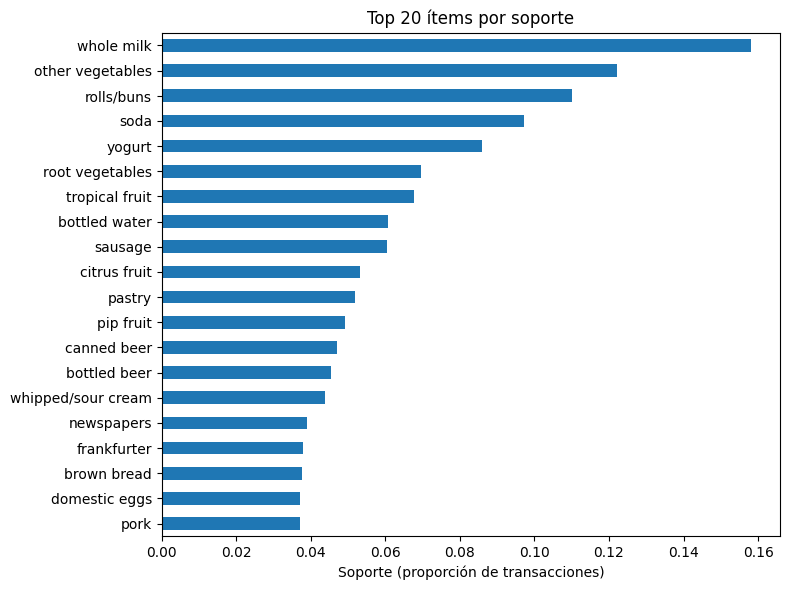

In [8]:
soporte_items = onehot.mean().sort_values(ascending=False)
print("Resumen del soporte de los ítems individuales:")
print(soporte_items.describe().round(4))
print("\nPercentiles:")
print(soporte_items.quantile([0.5, 0.75, 0.9]).round(4))
for s in [0.05, 0.02, 0.01, 0.005, 0.002]:
    print(f"Ítems con soporte >= {s}: {(soporte_items >= s).sum()}")

soporte_items.head(20).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 20 ítems por soporte"); plt.xlabel("Soporte (proporción de transacciones)")
plt.tight_layout(); plt.show()

### Justificación del soporte mínimo
✍️ *Ejemplo (ajústalo con tus números):* El ítem más frecuente aparece en ~X% de las transacciones y la mitad de los ítems tiene soporte menor a Y. Las canastas son pequeñas (≈2 ítems), así que los pares de productos son poco frecuentes. Con soporte 0.01 casi no aparecen pares; por eso elijo **0.003**, que deja varias decenas de ítems frecuentes y permite encontrar pares sin generar una cantidad inmanejable de itemsets.

In [9]:
from mlxtend.frequent_patterns import apriori, association_rules

MIN_SUPPORT = 0.003   # ✍️ ajusta según tu justificación

itemsets = apriori(onehot, min_support=MIN_SUPPORT, use_colnames=True)
itemsets["largo"] = itemsets["itemsets"].apply(len)
print("Itemsets frecuentes:", len(itemsets))
print(itemsets["largo"].value_counts().sort_index().rename("cantidad por tamaño"))
itemsets.sort_values("support", ascending=False).head(15)

Itemsets frecuentes: 209
largo
1    110
2     99
Name: cantidad por tamaño, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets,largo
107,0.157986,(whole milk),1
66,0.122150,(other vegetables),1
81,0.110049,(rolls/buns),1
89,0.097145,(soda),1
108,0.085913,(yogurt),1
82,0.069600,(root vegetables),1
99,0.067794,(tropical fruit),1
5,0.060707,(bottled water),1
85,0.060373,(sausage),1
20,0.053152,(citrus fruit),1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Fase 4 · Reglas de asociación
- **Soporte** de la regla A→B: proporción de transacciones con A y B juntos.
- **Confianza**: de las transacciones que tienen A, qué proporción también tiene B.
- **Lift** = confianza / soporte(B). Si lift > 1, A y B aparecen juntos **más** de lo esperado por azar; si ≈ 1 no hay relación; si < 1 se "evitan".

Ordeno por **lift** (y luego confianza), porque la confianza sola favorece a los productos que todo el mundo compra.

In [10]:
def generar_reglas(itemsets, min_conf):
    if len(itemsets) == 0:
        return pd.DataFrame()
    try:   # versiones nuevas de mlxtend piden num_itemsets
        r = association_rules(itemsets, metric="confidence", min_threshold=min_conf,
                              num_itemsets=len(onehot))
    except TypeError:
        r = association_rules(itemsets, metric="confidence", min_threshold=min_conf)
    if len(r):
        r["antecedente"] = r["antecedents"].apply(lambda s: ", ".join(sorted(s)))
        r["consecuente"] = r["consequents"].apply(lambda s: ", ".join(sorted(s)))
    return r

MIN_CONF = 0.05   # ✍️ ajusta
reglas = generar_reglas(itemsets, MIN_CONF)
print("Reglas generadas:", len(reglas))
cols = ["antecedente", "consecuente", "support", "confidence", "lift"]
reglas = reglas.sort_values(["lift", "confidence"], ascending=False)
reglas[cols].round(4).head(20)

Reglas generadas: 125


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedente,consecuente,support,confidence,lift
3,bottled beer,sausage,0.0033,0.0737,1.2215
4,sausage,bottled beer,0.0033,0.0554,1.2215
40,frankfurter,other vegetables,0.0051,0.1363,1.1157
108,sausage,yogurt,0.0057,0.0952,1.1085
109,yogurt,sausage,0.0057,0.0669,1.1085
73,pastry,sausage,0.0032,0.0620,1.0272
72,sausage,pastry,0.0032,0.0532,1.0272
104,sausage,soda,0.0060,0.0986,1.0146
103,soda,sausage,0.0060,0.0613,1.0146
32,citrus fruit,yogurt,0.0046,0.0868,1.0102


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Experimento: comparación de umbrales
Repito Apriori + reglas con varias combinaciones de soporte y confianza mínimos.

In [11]:
configs = [
    (0.010, 0.10),
    (0.005, 0.10),
    (0.003, 0.05),
    (0.002, 0.05),
]
filas = []
for sup, conf in configs:
    its = apriori(onehot, min_support=sup, use_colnames=True)
    rr = generar_reglas(its, conf)
    filas.append({
        "soporte_min": sup, "confianza_min": conf,
        "n_itemsets": len(its),
        "n_itemsets_tam>=2": int((its["itemsets"].apply(len) >= 2).sum()) if len(its) else 0,
        "n_reglas": len(rr),
        "reglas_lift>1": int((rr["lift"] > 1).sum()) if len(rr) else 0,
        "lift_max": round(rr["lift"].max(), 3) if len(rr) else None,
    })
comparacion = pd.DataFrame(filas)
comparacion

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,soporte_min,confianza_min,n_itemsets,n_itemsets_tam>=2,n_reglas,reglas_lift>1,lift_max
0,0.010,0.10,68,5,4,0,0.823
1,0.005,0.10,124,36,18,1,1.116
2,0.003,0.05,209,99,125,11,1.222
3,0.002,0.05,321,196,212,22,1.446


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Conclusión del experimento
✍️ *Escribe 3–5 líneas con tus números. Guía:* al bajar el soporte mínimo aumentan los itemsets y las reglas (¿cuánto?); con soporte alto casi no hay reglas porque los pares son poco frecuentes; al subir la confianza se filtran muchas reglas; ¿cuántas reglas tienen lift > 1? ¿Qué configuración elegirías y por qué (equilibrio entre cantidad y calidad)?

### Verificación manual de una regla (como en la Actividad 2.5)
Compruebo a mano soporte, confianza y lift de la mejor regla, contando transacciones.

In [12]:
r0 = reglas.iloc[0]
A, B = set(r0["antecedents"]), set(r0["consequents"])
N = len(onehot)
tiene_A = onehot[list(A)].all(axis=1)
tiene_B = onehot[list(B)].all(axis=1)
n_A, n_B, n_AB = tiene_A.sum(), tiene_B.sum(), (tiene_A & tiene_B).sum()
print(f"Regla: {A} -> {B}")
print(f"N={N} | transacciones con A={n_A} | con B={n_B} | con A y B={n_AB}")
print(f"Soporte   = {n_AB}/{N} = {n_AB/N:.4f}   (librería: {r0['support']:.4f})")
print(f"Confianza = {n_AB}/{n_A} = {n_AB/n_A:.4f}   (librería: {r0['confidence']:.4f})")
print(f"Lift      = {(n_AB/n_A):.4f}/{(n_B/N):.4f} = {(n_AB/n_A)/(n_B/N):.4f}   (librería: {r0['lift']:.4f})")

# Muestra pequeña: algunas transacciones que contienen A, para mirarlas a ojo
print("\nEjemplos de transacciones que contienen A:")
for t in [t for t in transacciones if A.issubset(t)][:8]:
    print(" -", t, "→ contiene B" if B.issubset(t) else "")

Regla: {'bottled beer'} -> {'sausage'}
N=14957 | transacciones con A=678 | con B=903 | con A y B=50
Soporte   = 50/14957 = 0.0033   (librería: 0.0033)
Confianza = 50/678 = 0.0737   (librería: 0.0737)
Lift      = 0.0737/0.0604 = 1.2215   (librería: 1.2215)

Ejemplos de transacciones que contienen A:
 - ['whole milk', 'frankfurter', 'chicken', 'flour', 'chocolate', 'bottled beer', 'rolls/buns'] 
 - ['whole milk', 'sausage', 'bottled beer', 'yogurt'] → contiene B
 - ['uht-milk', 'bottled beer'] 
 - ['white bread', 'bottled beer', 'yogurt', 'berries'] 
 - ['hamburger meat', 'bottled beer'] 
 - ['bottled beer', 'oil'] 
 - ['soda', 'fruit/vegetable juice', 'bottled beer'] 
 - ['root vegetables', 'bottled beer'] 


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Fase 5 · Interpretación

In [13]:
# Candidatas a mejores reglas: lift > 1, ordenadas por lift
mejores = reglas[reglas["lift"] > 1].sort_values(["lift", "confidence"], ascending=False)
mejores[cols].round(3).head(15)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedente,consecuente,support,confidence,lift
3,bottled beer,sausage,0.003,0.074,1.222
4,sausage,bottled beer,0.003,0.055,1.222
40,frankfurter,other vegetables,0.005,0.136,1.116
108,sausage,yogurt,0.006,0.095,1.109
109,yogurt,sausage,0.006,0.067,1.109
73,pastry,sausage,0.003,0.062,1.027
72,sausage,pastry,0.003,0.053,1.027
104,sausage,soda,0.006,0.099,1.015
103,soda,sausage,0.006,0.061,1.015
32,citrus fruit,yogurt,0.005,0.087,1.010


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [14]:
# Candidatas a DESCARTAR: superan los umbrales pero tienen lift <= 1
# (suelen tener como consecuente un producto muy popular, p. ej. whole milk)
sospechosas = reglas[reglas["lift"] <= 1].sort_values("confidence", ascending=False)
print("Reglas que pasan los umbrales pero con lift <= 1:", len(sospechosas))
sospechosas[cols].round(3).head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Reglas que pasan los umbrales pero con lift <= 1: 114


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedente,consecuente,support,confidence,lift
5,bottled beer,whole milk,0.007,0.158,0.999
107,sausage,whole milk,0.009,0.148,0.939
54,newspapers,whole milk,0.006,0.144,0.914
39,domestic eggs,whole milk,0.005,0.142,0.901
48,hamburger meat,whole milk,0.003,0.141,0.890
43,frankfurter,whole milk,0.005,0.140,0.885
0,beef,whole milk,0.005,0.138,0.872
45,frozen vegetables,whole milk,0.004,0.136,0.861
83,pork,whole milk,0.005,0.135,0.855
79,pip fruit,whole milk,0.007,0.135,0.854


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Las 5 reglas más valiosas (en lenguaje de negocio)

1. **{bottled beer} → {sausage}** (soporte 0,003 · conf. 0,074 · lift 1,22): Los clientes que compran cerveza tienen un 22% más de probabilidad de llevar también salchichas que un cliente cualquiera.
2. **{frankfurter} → {other vegetables}** (soporte 0,005 · conf. 0,136 · lift 1,12): Quienes compran vienesas llevan verduras un 12% más seguido que el cliente promedio, probablemente para acompañar una comida.
3. **{sausage} → {yogurt}** (soporte 0,006 · conf. 0,095 · lift 1,11): Los clientes que compran salchichas llevan yogur un 11% más que el promedio; la relación es débil, pero es una de las combinaciones más frecuentes.
4. **{pastry} → {sausage}** (soporte 0,003 · conf. 0,062 · lift 1,03): Quien compra pasteles o masas también lleva salchichas un poco más de lo normal, lo que sugiere compras para una once o un picoteo.
5. **{citrus fruit} → {yogurt}** (soporte 0,005 · conf. 0,087 · lift 1,01): Los clientes que llevan cítricos compran yogur casi igual que el promedio; la relación existe pero es mínima, así que sirve solo como apoyo.

> Nota: todos los lift están entre 1,01 y 1,22, por lo que son asociaciones débiles. Las más confiables para tomar decisiones son las tres primeras.

### Regla descartada
**{bottled beer} → {whole milk}** — soporte 0,007 · confianza 0,158 · lift 0,999.

Aunque supera los umbrales y tiene la confianza más alta (15,8%), su lift es menor que 1. La leche entera aparece en el 15,8% de **todas** las compras, exactamente lo mismo que la confianza de esta regla, así que comprar cerveza no aumenta en nada la probabilidad de comprar leche. Su "confianza alta" solo refleja que la leche es el producto más popular del almacén. Usarla para una promoción no aportaría nada.

### Decisión concreta para un administrador
Ubicar las **salchichas cerca de la sección de cervezas** y probar durante un mes un **pack cerveza + salchichas** con un pequeño descuento, comparando las ventas de salchichas con el mes anterior para ver si aumentan. Como segunda acción, poner verduras cerca de las vienesas. No conviene hacer promociones que combinen la leche con otros productos, porque la leche se vende igual por sí sola.

### Reflexión final
Aprendí que los umbrales cambian mucho el resultado: con soporte alto casi no hay reglas, y con soporte muy bajo aparecen muchas reglas basadas en pocas compras.
La confianza por sí sola engaña, porque favorece a los productos más populares como la leche; el lift es la métrica que muestra si una relación es real.
En este dataset las asociaciones fueron débiles (lift máximo 1,22), así que cualquier decisión debe probarse y medirse antes de aplicarse.
Además, las reglas solo muestran qué productos aparecen juntos, no que uno cause la compra del otro, y no son un modelo predictivo.